# Chapter 12: Cross-Validation and Model Evaluation Techniques

*Summary notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 12.*

Chapter ini membahas cara memperkirakan kemampuan generalisasi model, memilih metrik evaluasi, dan membandingkan konfigurasi model secara lebih andal. Fokusnya bukan sekadar memperoleh skor tinggi, tetapi memastikan skor tersebut mewakili performa pada data yang belum pernah dilihat model.

**Chapter at a glance**

| Recipe | Core idea |
|:--|:--|
| Introduction to cross-validation | K-Fold dan Stratified K-Fold |
| Advanced cross-validation methods | Leave-One-Out dan Nested CV |
| Model evaluation metrics overview | Metrik klasifikasi dan regresi |
| Implementing cross-validation in scikit-learn | `cross_val_score`, `cross_validate`, `GridSearchCV` |
| Model selection techniques | Grid Search dan Randomized Search |
| Evaluating model generalizability | Learning curve dan validation curve |

Semua contoh menggunakan dataset sintetis atau dataset bawaan scikit-learn; tidak membutuhkan unduhan dataset eksternal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import warnings
warnings.filterwarnings("ignore")

print("scikit-learn version:", sklearn.__version__)
print("NumPy version:", np.__version__)

scikit-learn version: 1.8.0
NumPy version: 2.3.5


> **Catatan versi.** Buku menggunakan scikit-learn 1.5+. Contoh di bawah disusun agar kompatibel dengan versi scikit-learn modern. Hasil numerik dapat sedikit berbeda antarversi.

## 1. Introduction to Cross-Validation

### Summary

**Cross-validation (CV)** membagi dataset menjadi beberapa bagian (*folds*). Model dilatih berulang kali menggunakan sebagian fold dan divalidasi pada fold yang tersisa. Rata-rata skor dari seluruh iterasi menjadi estimasi performa yang lebih stabil dibanding satu kali train-test split.

### K-Fold

Pada K-Fold dengan jumlah fold $k$, setiap iterasi menggunakan $k-1$ fold untuk training dan satu fold untuk validation. Setiap sampel menjadi data validasi tepat satu kali.

### Stratified K-Fold

Untuk klasifikasi, **StratifiedKFold** mempertahankan proporsi kelas pada setiap fold. Ini penting ketika distribusi kelas tidak seimbang.

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = make_classification(
    n_samples=500, n_features=10, n_informative=8,
    n_redundant=2, weights=[0.7, 0.3], random_state=2024
)

kf = KFold(n_splits=5, shuffle=True, random_state=2024)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)

def evaluate_splitter(splitter, X, y):
    scores = []
    for train_idx, valid_idx in splitter.split(X, y):
        model = LogisticRegression(max_iter=1000)
        model.fit(X[train_idx], y[train_idx])
        pred = model.predict(X[valid_idx])
        scores.append(accuracy_score(y[valid_idx], pred))
    return np.array(scores)

kfold_scores = evaluate_splitter(kf, X, y)
stratified_scores = evaluate_splitter(skf, X, y)
print("K-Fold scores:", np.round(kfold_scores, 3))
print("K-Fold mean accuracy:", round(kfold_scores.mean(), 3))
print("Stratified K-Fold scores:", np.round(stratified_scores, 3))
print("Stratified mean accuracy:", round(stratified_scores.mean(), 3))

K-Fold scores: [0.73 0.75 0.81 0.72 0.76]
K-Fold mean accuracy: 0.754
Stratified K-Fold scores: [0.74 0.74 0.8  0.74 0.82]
Stratified mean accuracy: 0.768


**Reading the output.** Nilai rata-rata menunjukkan performa lintas fold, sedangkan variasi skor menunjukkan seberapa sensitif hasil terhadap pembagian data. Stratified K-Fold umumnya lebih representatif untuk klasifikasi dengan kelas tidak seimbang karena rasio kelas dipertahankan pada setiap fold.

## 2. Advanced Cross-Validation Methods

### Summary

Dua metode lanjutan yang dibahas dalam buku:

- **Leave-One-Out Cross-Validation (LOOCV):** satu sampel menjadi validation dan seluruh sampel lain menjadi training. Proses diulang untuk setiap sampel. Pemanfaatan data maksimal, tetapi komputasinya dapat mahal.
- **Nested Cross-Validation:** CV bagian dalam memilih hyperparameter, sedangkan CV bagian luar mengevaluasi proses pemilihan tersebut. Pemisahan ini membantu mencegah estimasi performa yang terlalu optimistis akibat tuning pada data evaluasi.

Contoh menggunakan dataset diabetes bawaan untuk tugas regresi.

In [3]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

diabetes = load_diabetes()
X_reg, y_reg = diabetes.data, diabetes.target

loo = LeaveOneOut()
loo_scores = cross_val_score(
    Ridge(alpha=1.0), X_reg, y_reg,
    cv=loo, scoring="neg_mean_squared_error", n_jobs=-1
)
print("LOOCV mean MSE:", round(-loo_scores.mean(), 2))

param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}
inner_search = GridSearchCV(Ridge(), param_grid, cv=5, scoring="neg_mean_squared_error")
nested_scores = cross_val_score(
    inner_search, X_reg, y_reg, cv=5,
    scoring="neg_mean_squared_error", n_jobs=-1
)
print("Nested CV mean MSE:", round(-nested_scores.mean(), 2))

LOOCV mean MSE: 3327.66
Nested CV mean MSE: 3004.95


**Interpretasi.** MSE yang lebih kecil menunjukkan kesalahan prediksi yang lebih rendah. LOOCV menjalankan banyak iterasi (sebanyak jumlah sampel). Nested CV lebih tepat ketika proses tuning hyperparameter juga harus dievaluasi secara independen. Jangan membandingkan skor dari metrik atau skema CV yang berbeda tanpa memperhatikan konteksnya.

## 3. Model Evaluation Metrics Overview

### Summary

Pemilihan metrik harus mengikuti tujuan masalah. **Accuracy** dapat menyesatkan pada data tidak seimbang. Untuk klasifikasi, precision mengukur ketepatan prediksi positif, recall mengukur proporsi positif aktual yang berhasil ditemukan, dan F1 merupakan harmonic mean precision dan recall.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN}$$

$$F1=2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

Untuk regresi, metrik umum meliputi **MAE** (rata-rata kesalahan absolut), **MSE** (rata-rata kuadrat kesalahan), **RMSE** (akar MSE), dan $R^2$ (proporsi variasi target yang dijelaskan model).

In [4]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=2024
)
clf = RandomForestClassifier(n_estimators=150, random_state=2024)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1       :", round(f1_score(y_test, y_pred), 3))

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=2024
)
reg = RandomForestRegressor(n_estimators=150, random_state=2024)
reg.fit(Xr_train, yr_train)
yr_pred = reg.predict(Xr_test)
print("\nRegression metrics")
print("MAE :", round(mean_absolute_error(yr_test, yr_pred), 2))
print("MSE :", round(mean_squared_error(yr_test, yr_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(yr_test, yr_pred)), 2))
print("R2  :", round(r2_score(yr_test, yr_pred), 3))

Accuracy : 0.864
Precision: 0.867
Recall   : 0.667
F1       : 0.754



Regression metrics
MAE : 46.06
MSE : 3203.15
RMSE: 56.6
R2  : 0.476


**Interpretasi.** Jika false negative berbiaya tinggi (misalnya skrining penyakit), recall dapat lebih penting. Jika false positive mahal, precision dapat lebih diprioritaskan. Untuk regresi, MAE lebih mudah dibaca dalam satuan target, sedangkan MSE/RMSE memberi penalti lebih besar pada error yang besar. $R^2$ mendekati 1 biasanya lebih baik, tetapi dapat bernilai negatif pada model yang lebih buruk daripada baseline rata-rata.

## 4. Implementing Cross-Validation in scikit-learn

### Summary

scikit-learn menyediakan API tingkat tinggi:

- `cross_val_score()` menghitung skor CV untuk satu metrik.
- `cross_validate()` dapat menghitung beberapa metrik sekaligus dan mengembalikan waktu fit/score.
- `GridSearchCV()` menggabungkan CV dengan pencarian kombinasi hyperparameter.

Gunakan `scoring` yang sesuai dengan tujuan model. Untuk klasifikasi tidak seimbang, pertimbangkan precision, recall, atau F1 selain accuracy.

In [5]:
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV

base_model = LogisticRegression(max_iter=1000)
accuracy_scores = cross_val_score(
    base_model, X, y, cv=5, scoring="accuracy"
)
print("Fold accuracy:", np.round(accuracy_scores, 3))
print("Mean accuracy:", round(accuracy_scores.mean(), 3))

multi_results = cross_validate(
    base_model, X, y, cv=5,
    scoring=["accuracy", "precision", "recall", "f1"]
)
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"Mean {metric}: {multi_results['test_' + metric].mean():.3f}")

search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid={"C": [0.01, 0.1, 1, 10]},
    cv=5, scoring="f1"
)
search.fit(X, y)
print("Best parameters:", search.best_params_)
print("Best mean CV F1:", round(search.best_score_, 3))

Fold accuracy: [0.8  0.72 0.74 0.77 0.78]
Mean accuracy: 0.762
Mean accuracy: 0.762
Mean precision: 0.675
Mean recall: 0.458
Mean f1: 0.544
Best parameters: {'C': 10}
Best mean CV F1: 0.55


**Reading the output.** `cross_val_score` menghasilkan satu skor per fold. `cross_validate` menyimpan skor untuk setiap metrik yang diminta. `GridSearchCV` memilih kombinasi parameter dengan skor CV terbaik. Perlu diingat bahwa `best_score_` adalah skor validasi silang, bukan skor final pada test set independen.

## 5. Model Selection Techniques

### Summary

**Grid Search** mencoba seluruh kombinasi parameter yang didefinisikan. **Randomized Search** mengambil sejumlah kombinasi secara acak dari distribusi parameter. Grid Search cocok untuk ruang pencarian kecil; Randomized Search dapat lebih hemat ketika ruang parameter besar.

Prosedur yang benar: pisahkan test set terlebih dahulu, lakukan pencarian parameter hanya pada training set, lalu evaluasi estimator terbaik pada test set yang tidak digunakan selama tuning.

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
from sklearn.metrics import accuracy_score

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=2024
)
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000), param_grid,
    cv=5, scoring="f1", n_jobs=-1
)
grid_search.fit(Xtr, ytr)

param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(
    LogisticRegression(max_iter=1000),
    param_distributions=param_dist, n_iter=10,
    cv=5, scoring="f1", random_state=2024, n_jobs=-1
)
random_search.fit(Xtr, ytr)

for name, candidate in [("Grid", grid_search), ("Randomized", random_search)]:
    test_pred = candidate.best_estimator_.predict(Xte)
    print(name, "best params:", candidate.best_params_)
    print(name, "best CV F1:", round(candidate.best_score_, 3))
    print(name, "test accuracy:", round(accuracy_score(yte, test_pred), 3))

Grid best params: {'C': 0.1}
Grid best CV F1: 0.479
Grid test accuracy: 0.807
Randomized best params: {'C': np.float64(0.17437295301054892)}
Randomized best CV F1: 0.477
Randomized test accuracy: 0.8


**Interpretasi.** Grid Search mengevaluasi semua nilai `C` yang ditentukan, sedangkan Randomized Search mengambil sampel dari distribusi log-uniform. Hasil terbaik tidak harus identik. Bandingkan skor CV dan test secara terpisah; selisih besar dapat menjadi indikasi bahwa estimasi CV belum sepenuhnya mencerminkan performa pada data baru.

## 6. Evaluating Model Generalizability

### Summary

Model yang bagus pada training data belum tentu mampu melakukan generalisasi. Distribusi data produksi juga dapat berubah seiring waktu (*data drift*), sehingga evaluasi berkala dan retraining mungkin diperlukan.

- **Learning curve** menunjukkan skor training dan cross-validation ketika jumlah data training bertambah. Gap besar dapat mengindikasikan overfitting; kedua kurva yang rendah dapat mengindikasikan underfitting.
- **Validation curve** menunjukkan perubahan skor training dan validation ketika satu hyperparameter diubah. Kurva membantu mengamati efek kompleksitas model dan regularisasi.

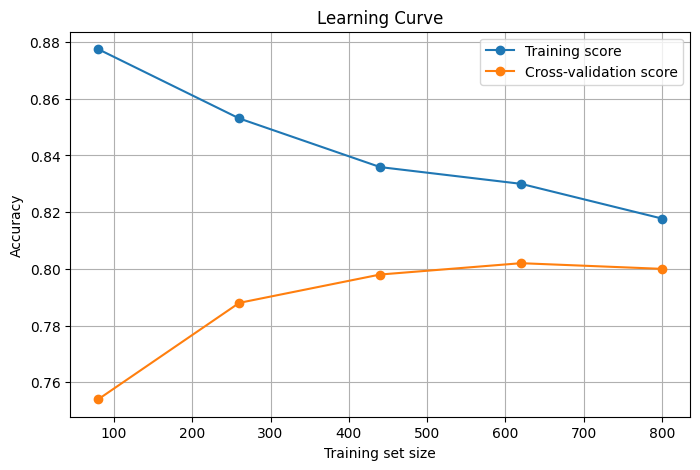

Training scores: [0.878 0.853 0.836 0.83  0.818]
CV scores: [0.754 0.788 0.798 0.802 0.8  ]


In [7]:
from sklearn.model_selection import learning_curve, validation_curve

X_curve, y_curve = make_classification(
    n_samples=1000, n_features=20, n_informative=8,
    weights=[0.7, 0.3], random_state=2024
)
curve_model = LogisticRegression(max_iter=1000)
train_sizes, train_scores, valid_scores = learning_curve(
    curve_model, X_curve, y_curve, cv=5,
    scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training score")
plt.plot(train_sizes, valid_mean, marker="o", label="Cross-validation score")
plt.xlabel("Training set size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)
plt.show()
print("Training scores:", np.round(train_mean, 3))
print("CV scores:", np.round(valid_mean, 3))

**Membaca learning curve.** Perhatikan apakah skor validation meningkat saat data bertambah dan apakah jarak antara training dan validation mengecil. Jika keduanya mulai mendatar, penambahan data mungkin memberi peningkatan yang semakin kecil.

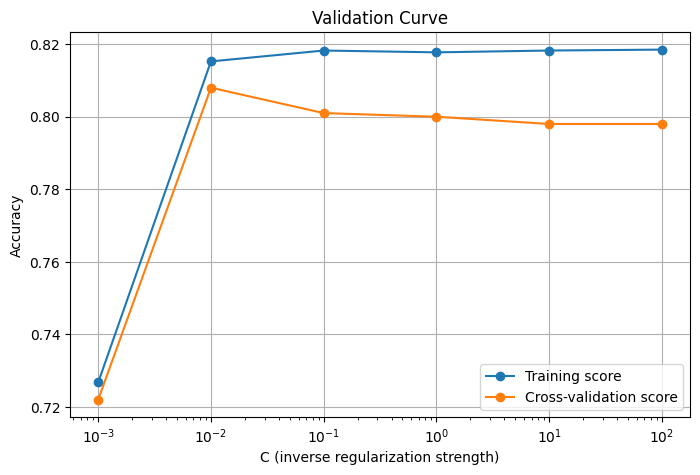

C values: [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02]
Mean CV scores: [0.722 0.808 0.801 0.8   0.798 0.798]


In [8]:
param_range = np.logspace(-3, 2, 6)
train_scores, valid_scores = validation_curve(
    LogisticRegression(max_iter=1000), X_curve, y_curve,
    param_name="C", param_range=param_range,
    cv=5, scoring="accuracy", n_jobs=-1
)
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.semilogx(param_range, train_mean, marker="o", label="Training score")
plt.semilogx(param_range, valid_mean, marker="o", label="Cross-validation score")
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("Accuracy")
plt.title("Validation Curve")
plt.legend()
plt.grid(True)
plt.show()
print("C values:", param_range)
print("Mean CV scores:", np.round(valid_mean, 3))

**Membaca validation curve.** Pada Logistic Regression, `C` kecil berarti regularisasi lebih kuat; `C` besar berarti regularisasi lebih lemah. Skor training yang tinggi tetapi skor validation lebih rendah dapat menunjukkan overfitting. Pilih nilai parameter berdasarkan performa validation dan kebutuhan generalisasi, bukan hanya training score.

## 7. Chapter Summary and Practice

### Key takeaways

1. Cross-validation memberi estimasi performa yang lebih stabil daripada satu pembagian data.
2. Stratified K-Fold mempertahankan distribusi kelas dan berguna untuk klasifikasi, khususnya data tidak seimbang.
3. LOOCV menggunakan hampir seluruh data untuk training pada setiap iterasi, tetapi mahal secara komputasi.
4. Nested CV memisahkan proses tuning dan evaluasi untuk mengurangi bias pemilihan model.
5. Pilih metrik sesuai konsekuensi kesalahan; accuracy bukan selalu pilihan terbaik.
6. Grid Search mencoba semua kombinasi yang ditentukan, sedangkan Randomized Search mengambil sampel kombinasi.
7. Learning curve dan validation curve membantu mendiagnosis generalisasi dan kompleksitas model.

### Latihan mandiri

- Ubah `n_splits` pada StratifiedKFold menjadi 3 dan 10. Bandingkan rata-rata serta variasi skor.
- Bandingkan LOOCV dan K-Fold pada dataset regresi yang sama.
- Ubah metrik `GridSearchCV` dari `accuracy` menjadi `f1` dan amati apakah parameter terbaik berubah.
- Perluas rentang `C` pada validation curve. Identifikasi wilayah underfitting, performa terbaik, dan kemungkinan overfitting.
- Jelaskan mengapa test set tidak boleh digunakan untuk memilih hyperparameter.

### Kesimpulan

Evaluasi model yang baik membutuhkan pembagian data yang tepat, metrik yang sesuai, dan proses pemilihan model yang tidak mencemari data evaluasi. Cross-validation, model search, serta kurva diagnostik saling melengkapi untuk menghasilkan model yang lebih siap menghadapi data baru.